# Task 3: Customer Cohort & Churn Analytics
**Datheon Data Analytics & Power BI Internship**

Dataset: IBM Telco Customer Churn

**Objectives**
1. Calculate baseline churn rate
2. Segment customers by tenure cohort, contract, payment method and monthly charges
3. Build the cohort retention matrix
4. Identify high-risk segments (e.g. Fiber Optic without Tech Support)
5. Export a clean file for the Power BI dashboard

## Step 1: Import libraries and load data

In [1]:
import re
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
from pathlib import Path

pd.set_option("display.max_columns", 50)

DATA_PATH = "Data/telco_customer_churn.csv"
OUT_DIR = Path("outputs")
OUT_DIR.mkdir(exist_ok=True)

df = pd.read_csv(DATA_PATH)
print(df.shape)
df.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


### Helper: static charts
Plotly charts are saved as interactive HTML files in the `outputs` folder.
The charts below are also drawn as static images with matplotlib so they show up everywhere,
including the GitHub notebook preview.

In [2]:
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

def static_bar(labels, values, title, ylabel="Churn Rate %", horizontal=False, color="#d64545"):
    labels = [str(l) for l in labels]
    values = [float(v) for v in values]
    fig, ax = plt.subplots(figsize=(7, 3.6))
    if horizontal:
        bars = ax.barh(labels[::-1], values[::-1], color=color)
        for b, v in zip(bars, values[::-1]):
            ax.text(v + 0.5, b.get_y() + b.get_height() / 2, f"{v:.2f}%", va="center", fontsize=9)
        ax.set_xlabel(ylabel)
    else:
        bars = ax.bar(labels, values, color=color)
        for b, v in zip(bars, values):
            ax.text(b.get_x() + b.get_width() / 2, v + 0.5, f"{v:.2f}%", ha="center", fontsize=9)
        ax.set_ylabel(ylabel)
        plt.xticks(rotation=15)
    ax.set_title(title, loc="left", fontsize=11)
    plt.tight_layout()
    plt.show()

def static_heat(matrix, title, cmap="Reds"):
    fig, ax = plt.subplots(figsize=(7.5, 3.2))
    im = ax.imshow(matrix.values.astype(float), cmap=cmap, aspect="auto")
    ax.set_xticks(range(matrix.shape[1])); ax.set_xticklabels([str(c) for c in matrix.columns])
    ax.set_yticks(range(matrix.shape[0])); ax.set_yticklabels([str(i) for i in matrix.index])
    for i in range(matrix.shape[0]):
        for j in range(matrix.shape[1]):
            v = matrix.values[i, j]
            if pd.notna(v):
                ax.text(j, i, f"{v:.1f}%", ha="center", va="center", fontsize=9)
    ax.set_title(title, loc="left", fontsize=11)
    fig.colorbar(im, ax=ax, fraction=0.03)
    plt.tight_layout()
    plt.show()

## Step 2: Standardise column names
Kaggle and IBM versions of the Telco file use slightly different column names.
This cell renames them so the rest of the notebook works with either version.

In [3]:
def norm(c):
    return re.sub(r"[^a-z0-9]", "", str(c).lower())

rename_map = {
    "customerid": "customerID",
    "tenure": "tenure",
    "tenuremonths": "tenure",
    "contract": "Contract",
    "paymentmethod": "PaymentMethod",
    "monthlycharges": "MonthlyCharges",
    "monthlycharge": "MonthlyCharges",
    "totalcharges": "TotalCharges",
    "internetservice": "InternetService",
    "internettype": "InternetType",
    "techsupport": "TechSupport",
    "premiumtechsupport": "TechSupport",
    "churn": "Churn",
    "churnlabel": "Churn",
    "churnvalue": "ChurnValue",
    "gender": "gender",
    "seniorcitizen": "SeniorCitizen",
    "paperlessbilling": "PaperlessBilling",
}

df = df.rename(columns={c: rename_map[norm(c)] for c in df.columns if norm(c) in rename_map})

# IBM version: "Internet Service" is Yes/No and "Internet Type" holds DSL/Fiber Optic/Cable
if "InternetType" in df.columns:
    df["InternetService"] = df["InternetType"].fillna("No")

required = ["tenure", "Contract", "PaymentMethod", "MonthlyCharges", "TotalCharges",
            "InternetService", "TechSupport"]
missing = [c for c in required if c not in df.columns]
print("Missing columns:", missing)
print(list(df.columns))

Missing columns: []
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


## Step 3: Clean the data
- `TotalCharges` has blank values for new customers (tenure = 0). Convert to number and fill with 0.
- Create `ChurnFlag` (1 = churned, 0 = stayed).

In [4]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("Blank TotalCharges:", df["TotalCharges"].isna().sum())
df["TotalCharges"] = df["TotalCharges"].fillna(0)

if "Churn" in df.columns and not pd.api.types.is_numeric_dtype(df["Churn"]):
    df["ChurnFlag"] = (df["Churn"].astype(str).str.strip().str.lower() == "yes").astype(int)
elif "ChurnValue" in df.columns:
    df["ChurnFlag"] = df["ChurnValue"].astype(int)
else:
    df["ChurnFlag"] = df["Churn"].astype(int)

df["Churn"] = np.where(df["ChurnFlag"] == 1, "Yes", "No")

print("Duplicates:", df.duplicated().sum())
print("Nulls in key columns:")
print(df[["tenure", "Contract", "PaymentMethod", "MonthlyCharges", "ChurnFlag"]].isna().sum())

Blank TotalCharges: 11
Duplicates: 0
Nulls in key columns:
tenure            0
Contract          0
PaymentMethod     0
MonthlyCharges    0
ChurnFlag         0
dtype: int64


## Step 4: Baseline churn rate
Churn Rate % = (Churned Customers / Total Customers) x 100

In [5]:
total_customers = len(df)
churned = int(df["ChurnFlag"].sum())
churn_rate = churned / total_customers * 100

print(f"Total Customers  : {total_customers}")
print(f"Churned Customers: {churned}")
print(f"Churn Rate       : {churn_rate:.2f}%")
print(f"Retention Rate   : {100 - churn_rate:.2f}%")

Total Customers  : 7043
Churned Customers: 1869
Churn Rate       : 26.54%
Retention Rate   : 73.46%


## Step 5: Tenure cohorts (0-12, 13-24, 25-48, 49-60, 61-72 months)

In [6]:
bins = [-1, 12, 24, 48, 60, 72]
labels = ["0-12 months", "13-24 months", "25-48 months", "49-60 months", "61-72 months"]
df["TenureCohort"] = pd.cut(df["tenure"], bins=bins, labels=labels)
cohort_order = {lbl: i + 1 for i, lbl in enumerate(labels)}
df["CohortOrder"] = df["TenureCohort"].map(cohort_order).astype(int)

cohort_tbl = (df.groupby("TenureCohort", observed=True)["ChurnFlag"]
                .agg(Customers="count", Churned="sum", ChurnRate="mean"))
cohort_tbl["ChurnRate"] = (cohort_tbl["ChurnRate"] * 100).round(2)
cohort_tbl["RetentionRate"] = (100 - cohort_tbl["ChurnRate"]).round(2)
cohort_tbl

,Customers,Churned,ChurnRate,RetentionRate
TenureCohort,,,,
0-12 months,2186,1037,47.44,52.56
13-24 months,1024,294,28.71,71.29
25-48 months,1594,325,20.39,79.61
49-60 months,832,120,14.42,85.58
61-72 months,1407,93,6.61,93.39


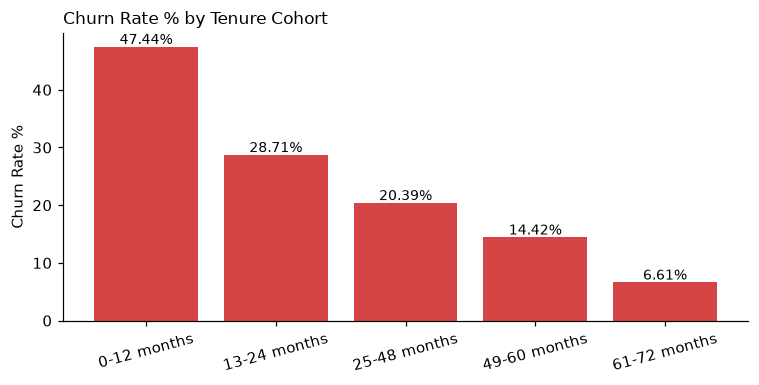

In [7]:
fig = px.bar(cohort_tbl.reset_index(), x="TenureCohort", y="ChurnRate", text="ChurnRate",
             title="Churn Rate % by Tenure Cohort", color="ChurnRate",
             color_continuous_scale="Reds")
fig.update_traces(texttemplate="%{text:.1f}%", textposition="outside")
fig.update_layout(yaxis_title="Churn Rate %", xaxis_title="Tenure Cohort")
fig.write_html(OUT_DIR / "01_churn_by_tenure_cohort.html")
static_bar(cohort_tbl.index, cohort_tbl["ChurnRate"], "Churn Rate % by Tenure Cohort")

## Step 6: Churn by contract type

,Customers,Churned,ChurnRate
Contract,,,
Month-to-month,3875,1655,42.71
One year,1473,166,11.27
Two year,1695,48,2.83


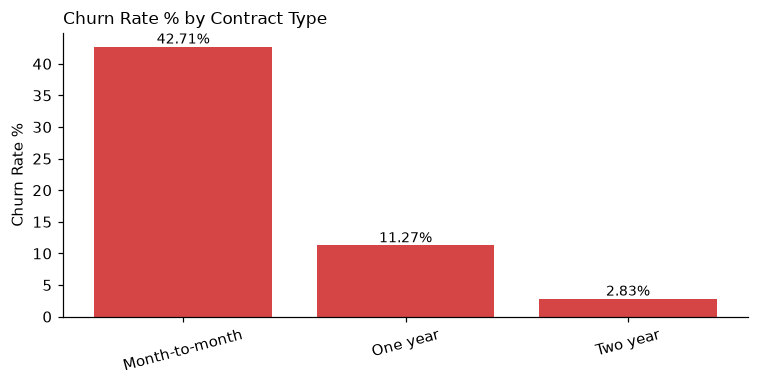

In [8]:
contract_tbl = (df.groupby("Contract")["ChurnFlag"]
                  .agg(Customers="count", Churned="sum", ChurnRate="mean"))
contract_tbl["ChurnRate"] = (contract_tbl["ChurnRate"] * 100).round(2)
display(contract_tbl)

fig = px.bar(contract_tbl.reset_index(), x="Contract", y="ChurnRate", text="ChurnRate",
             title="Churn Rate % by Contract Type", color="ChurnRate", color_continuous_scale="Reds")
fig.update_traces(texttemplate="%{text:.1f}%", textposition="outside")
fig.write_html(OUT_DIR / "02_churn_by_contract.html")
static_bar(contract_tbl.index, contract_tbl["ChurnRate"], "Churn Rate % by Contract Type")

## Step 7: Cohort retention matrix (main deliverable)
Rows = Contract type, Columns = Tenure cohort. First the churn matrix, then the retention matrix (100 - churn).

In [9]:
churn_matrix = (df.pivot_table(index="Contract", columns="TenureCohort", values="ChurnFlag",
                               aggfunc="mean", observed=True) * 100).round(1)
retention_matrix = (100 - churn_matrix).round(1)
count_matrix = df.pivot_table(index="Contract", columns="TenureCohort", values="ChurnFlag",
                              aggfunc="count", observed=True)

print("Churn % matrix")
display(churn_matrix)
print("Retention % matrix")
display(retention_matrix)
print("Customer count matrix (small counts = less reliable)")
display(count_matrix)

Churn % matrix


TenureCohort,0-12 months,13-24 months,25-48 months,49-60 months,61-72 months
Contract,,,,,
Month-to-month,51.4,37.7,32.9,27.8,22.2
One year,10.5,8.1,10.6,13.7,12.1
Two year,0.0,0.0,2.2,4.0,3.1


Retention % matrix


TenureCohort,0-12 months,13-24 months,25-48 months,49-60 months,61-72 months
Contract,,,,,
Month-to-month,48.6,62.3,67.1,72.2,77.8
One year,89.5,91.9,89.4,86.3,87.9
Two year,100.0,100.0,97.8,96.0,96.9


Customer count matrix (small counts = less reliable)


TenureCohort,0-12 months,13-24 months,25-48 months,49-60 months,61-72 months
Contract,,,,,
Month-to-month,1994,737,802,234,108
One year,124,197,518,321,313
Two year,68,90,274,277,986


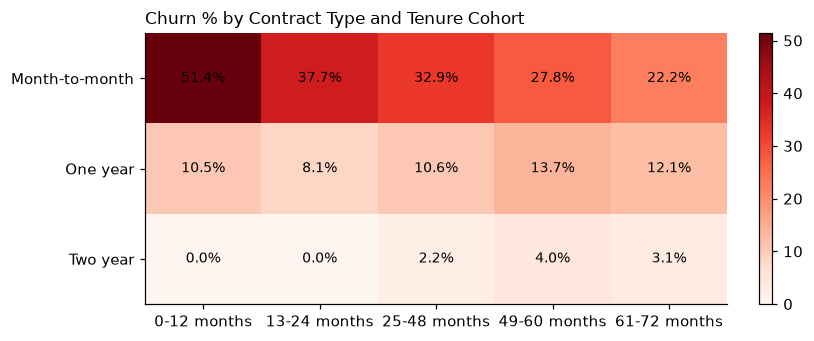

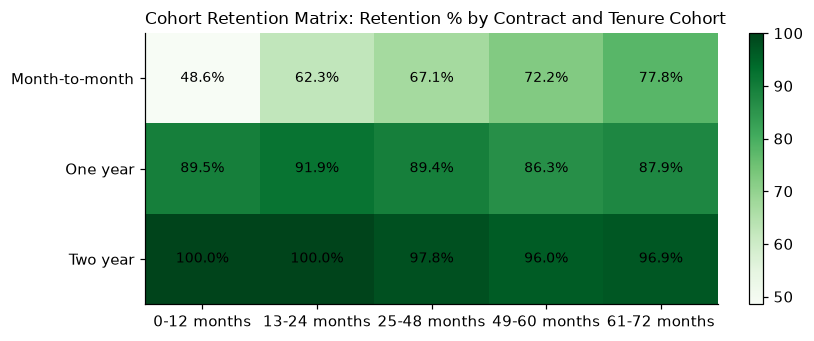

In [10]:
fig = px.imshow(churn_matrix, text_auto=".1f", color_continuous_scale="Reds", aspect="auto",
                title="Churn % by Contract Type and Tenure Cohort")
fig.update_layout(xaxis_title="Tenure Cohort", yaxis_title="Contract")
fig.write_html(OUT_DIR / "03_churn_heatmap_contract_tenure.html")
static_heat(churn_matrix, "Churn % by Contract Type and Tenure Cohort", "Reds")

fig = px.imshow(retention_matrix, text_auto=".1f", color_continuous_scale="Greens", aspect="auto",
                title="Cohort Retention Matrix: Retention % by Contract Type and Tenure Cohort")
fig.update_layout(xaxis_title="Tenure Cohort", yaxis_title="Contract")
fig.write_html(OUT_DIR / "04_retention_matrix_contract_tenure.html")
static_heat(retention_matrix, "Cohort Retention Matrix: Retention % by Contract and Tenure Cohort", "Greens")

## Step 8: Payment method

,Customers,Churned,ChurnRate
PaymentMethod,,,
Electronic check,2365,1071,45.29
Mailed check,1612,308,19.11
Bank transfer (automatic),1544,258,16.71
Credit card (automatic),1522,232,15.24


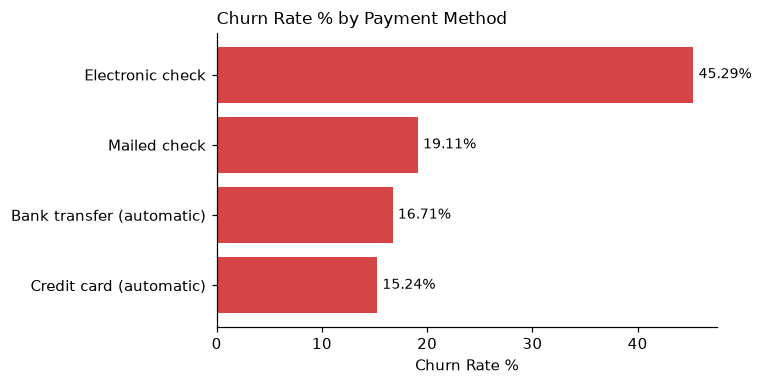

In [11]:
pay_tbl = (df.groupby("PaymentMethod")["ChurnFlag"]
             .agg(Customers="count", Churned="sum", ChurnRate="mean"))
pay_tbl["ChurnRate"] = (pay_tbl["ChurnRate"] * 100).round(2)
pay_tbl = pay_tbl.sort_values("ChurnRate", ascending=False)
display(pay_tbl)

fig = px.bar(pay_tbl.reset_index(), x="ChurnRate", y="PaymentMethod", orientation="h",
             text="ChurnRate", title="Churn Rate % by Payment Method",
             color="ChurnRate", color_continuous_scale="Reds")
fig.update_traces(texttemplate="%{text:.1f}%")
fig.update_layout(yaxis={"categoryorder": "total ascending"})
fig.write_html(OUT_DIR / "05_churn_by_payment.html")
static_bar(pay_tbl.index, pay_tbl["ChurnRate"], "Churn Rate % by Payment Method", horizontal=True)

## Step 9: Monthly charges bands

,Customers,MinCharge,MaxCharge,ChurnRate
ChargeBand,,,,
Low,1762,18.25,35.50,11.24
Mid,1766,35.55,70.35,24.58
High,1757,70.40,89.85,37.51
Premium,1758,89.90,118.75,32.88


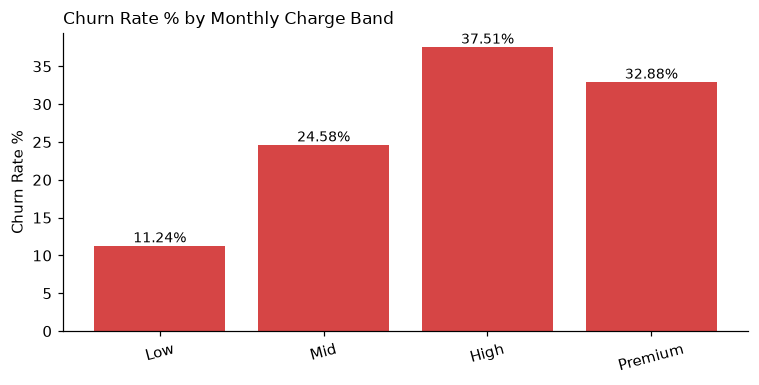

In [12]:
df["ChargeBand"] = pd.qcut(df["MonthlyCharges"], 4, labels=["Low", "Mid", "High", "Premium"])
df["ChargeBandOrder"] = df["ChargeBand"].cat.codes + 1

charge_tbl = (df.groupby("ChargeBand", observed=True)
                .agg(Customers=("ChurnFlag", "count"),
                     MinCharge=("MonthlyCharges", "min"),
                     MaxCharge=("MonthlyCharges", "max"),
                     ChurnRate=("ChurnFlag", "mean")))
charge_tbl["ChurnRate"] = (charge_tbl["ChurnRate"] * 100).round(2)
display(charge_tbl)

fig = px.bar(charge_tbl.reset_index(), x="ChargeBand", y="ChurnRate", text="ChurnRate",
             title="Churn Rate % by Monthly Charge Band", color="ChurnRate",
             color_continuous_scale="Reds")
fig.update_traces(texttemplate="%{text:.1f}%", textposition="outside")
fig.write_html(OUT_DIR / "06_churn_by_charge_band.html")
static_bar(charge_tbl.index, charge_tbl["ChurnRate"], "Churn Rate % by Monthly Charge Band")

## Step 10: Service tier and high-risk segments (Internet Service x Tech Support)

TechSupport,No,No internet service,Yes
InternetService,,,
DSL,27.8,NaN,9.7
Fiber optic,49.4,NaN,22.6
No,NaN,7.4,NaN


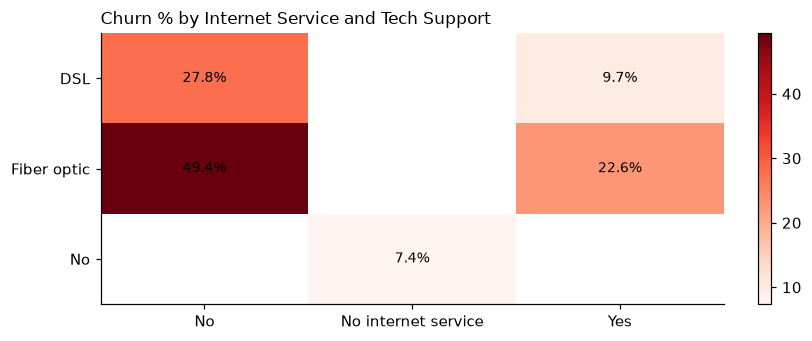

High-risk segment: Fiber Optic + No Tech Support
Customers  : 2230  (31.7% of base)
Churn Rate : 49.4%  (overall 26.5%)


In [13]:
df["IsFiber"] = df["InternetService"].astype(str).str.lower().str.contains("fiber")
df["NoTechSupport"] = df["TechSupport"].astype(str).str.strip().str.lower() == "no"

service_matrix = (df.pivot_table(index="InternetService", columns="TechSupport", values="ChurnFlag",
                                 aggfunc="mean") * 100).round(1)
display(service_matrix)

fig = px.imshow(service_matrix, text_auto=".1f", color_continuous_scale="Reds", aspect="auto",
                title="Churn % by Internet Service and Tech Support")
fig.write_html(OUT_DIR / "07_churn_heatmap_service_techsupport.html")
static_heat(service_matrix, "Churn % by Internet Service and Tech Support", "Reds")

risk = df[df["IsFiber"] & df["NoTechSupport"]]
print(f"High-risk segment: Fiber Optic + No Tech Support")
print(f"Customers  : {len(risk)}  ({len(risk) / len(df) * 100:.1f}% of base)")
print(f"Churn Rate : {risk['ChurnFlag'].mean() * 100:.1f}%  (overall {churn_rate:.1f}%)")

## Step 11: Combined high-risk segments
Combine Contract + Internet Service + Tech Support and rank by churn rate (only segments with 50+ customers).

In [14]:
seg = (df.groupby(["Contract", "InternetService", "TechSupport"])["ChurnFlag"]
         .agg(Customers="count", Churned="sum", ChurnRate="mean").reset_index())
seg["ChurnRate"] = (seg["ChurnRate"] * 100).round(1)
top_risk = seg[seg["Customers"] >= 50].sort_values("ChurnRate", ascending=False).head(10)
top_risk

,Contract,InternetService,TechSupport,Customers,Churned,ChurnRate
2,Month-to-month,Fiber optic,No,1796,1033,57.5
3,Month-to-month,Fiber optic,Yes,332,129,38.9
0,Month-to-month,DSL,No,884,317,35.9
1,Month-to-month,DSL,Yes,339,77,22.7
8,One year,Fiber optic,Yes,226,46,20.4
4,Month-to-month,No,No internet service,524,99,18.9
7,One year,Fiber optic,No,313,58,18.5
5,One year,DSL,No,244,24,9.8
6,One year,DSL,Yes,326,29,8.9
12,Two year,Fiber optic,No,121,10,8.3


## Step 12: Retention curves (Kaplan-Meier style, by contract)
Survival at month t = product of (1 - churned at month / customers still at risk).
Calculated manually so no extra library is needed.

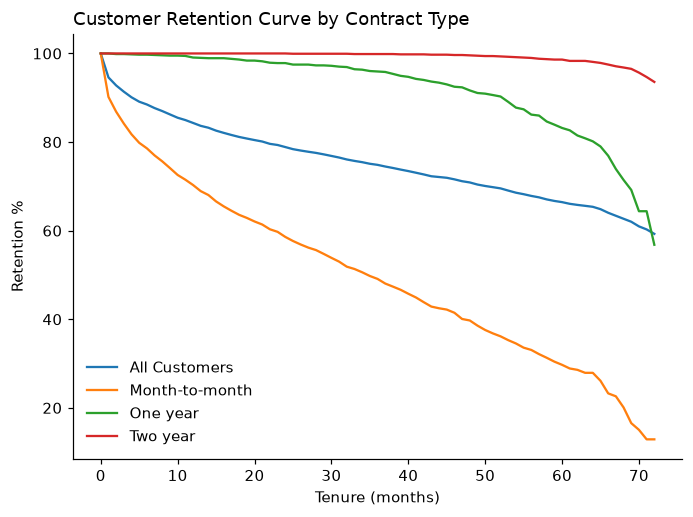

In [15]:
def retention_curve(sub):
    rows, surv = [], 1.0
    for t in range(0, int(df["tenure"].max()) + 1):
        at_risk = (sub["tenure"] >= t).sum()
        events = ((sub["tenure"] == t) & (sub["ChurnFlag"] == 1)).sum()
        if at_risk > 0:
            surv *= (1 - events / at_risk)
        rows.append((t, surv * 100))
    return pd.DataFrame(rows, columns=["Month", "Retention"])

curves = []
for name, sub in df.groupby("Contract"):
    c = retention_curve(sub)
    c["Contract"] = name
    curves.append(c)
curves.append(retention_curve(df).assign(Contract="All Customers"))
curves = pd.concat(curves)

fig = px.line(curves, x="Month", y="Retention", color="Contract",
              title="Customer Retention Curve by Contract Type")
fig.update_layout(yaxis_title="Retention %", xaxis_title="Tenure (months)")
fig.write_html(OUT_DIR / "08_retention_curve.html")
for name, grp in curves.groupby("Contract"):
    plt.plot(grp["Month"], grp["Retention"], label=name)
plt.title("Customer Retention Curve by Contract Type", loc="left")
plt.xlabel("Tenure (months)"); plt.ylabel("Retention %")
plt.legend(frameon=False); plt.tight_layout(); plt.show()

## Step 13: Export clean file for Power BI

In [16]:
export_cols = [c for c in df.columns if c not in ["IsFiber", "NoTechSupport"]]
df[export_cols].to_csv(OUT_DIR / "telco_churn_clean.csv", index=False)

churn_matrix.reset_index().to_csv(OUT_DIR / "churn_matrix.csv", index=False)
retention_matrix.reset_index().to_csv(OUT_DIR / "retention_matrix.csv", index=False)

print("Exported to:", OUT_DIR.resolve())
for f in sorted(OUT_DIR.iterdir()):
    print(" -", f.name)

Exported to: C:\Users\mdraf\Documents\Task_3\outputs
 - 01_churn_by_tenure_cohort.html
 - 02_churn_by_contract.html
 - 03_churn_heatmap_contract_tenure.html
 - 04_retention_matrix_contract_tenure.html
 - 05_churn_by_payment.html
 - 06_churn_by_charge_band.html
 - 07_churn_heatmap_service_techsupport.html
 - 08_retention_curve.html
 - churn_matrix.csv
 - retention_matrix.csv
 - telco_churn_clean.csv


## Step 14: Key findings summary (copy these numbers into your report)

In [17]:
worst_cohort = cohort_tbl["ChurnRate"].idxmax()
best_cohort = cohort_tbl["ChurnRate"].idxmin()
worst_contract = contract_tbl["ChurnRate"].idxmax()
best_contract = contract_tbl["ChurnRate"].idxmin()
worst_pay = pay_tbl["ChurnRate"].idxmax()
worst_band = charge_tbl["ChurnRate"].idxmax()

print("KEY FINDINGS")
print("-" * 60)
print(f"1. Overall churn rate: {churn_rate:.2f}% ({churned} of {total_customers} customers)")
print(f"2. Highest churn tenure cohort: {worst_cohort} ({cohort_tbl.loc[worst_cohort, 'ChurnRate']}%)")
print(f"   Lowest churn tenure cohort : {best_cohort} ({cohort_tbl.loc[best_cohort, 'ChurnRate']}%)")
print(f"3. Highest churn contract: {worst_contract} ({contract_tbl.loc[worst_contract, 'ChurnRate']}%)")
print(f"   Lowest churn contract : {best_contract} ({contract_tbl.loc[best_contract, 'ChurnRate']}%)")
print(f"4. Highest churn payment method: {worst_pay} ({pay_tbl.loc[worst_pay, 'ChurnRate']}%)")
print(f"5. Highest churn charge band: {worst_band} ({charge_tbl.loc[worst_band, 'ChurnRate']}%)")
print(f"6. Fiber Optic + No Tech Support: {risk['ChurnFlag'].mean() * 100:.1f}% churn "
      f"({len(risk)} customers)")

KEY FINDINGS
------------------------------------------------------------
1. Overall churn rate: 26.54% (1869 of 7043 customers)
2. Highest churn tenure cohort: 0-12 months (47.44%)
   Lowest churn tenure cohort : 61-72 months (6.61%)
3. Highest churn contract: Month-to-month (42.71%)
   Lowest churn contract : Two year (2.83%)
4. Highest churn payment method: Electronic check (45.29%)
5. Highest churn charge band: High (37.51%)
6. Fiber Optic + No Tech Support: 49.4% churn (2230 customers)
